# Please sign in to the workshop
## WORKSHOP ID: EH7c
## Link: http://tiny.cc/eh-sign-in

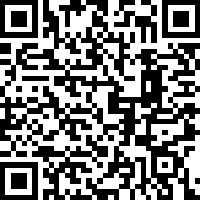

## Esther Hsiao: thsiao@olemiss.edu

## Workshop materials are available at: http://tiny.cc/eh-python

## Google Colab: https://colab.research.google.com/

## Try Jupyter: https://jupyter.org/try


The materials for this workshop were adapted from resources developed by Dr. Shelby Watson: [Python Basics Fall 2025](https://github.com/sawatson-um/pythonbasics_fall2025/tree/main)

# Week one recaps:
- Assigning variables
- Operators
- indexing and slicing
- if/elif/else

# Week two recaps:

- Importing libraries
- New data type: list
- For loop
- isinstance()
- range( ) and enumerate( )
- String: .split( ), .replace( ), .lower(), .upper(), and .title()
- Four ways for reading a file

# Week three topics:
- New data type: dictionary
- Write data to a file
- Pandas

In [42]:
import requests
import csv
from string import punctuation

import pandas as pd

In [43]:
# Code from week 2

# This cell downloads an ebook and save it to a text file (moby_dick.txt).

url = "https://www.gutenberg.org/cache/epub/2701/pg2701.txt"

response = requests.get(url)
book = response.content.decode("utf-8-sig")

# 'w' in with open(...) means write mode. It opens a file for writing.
# If the file does not exist, Python creates it.
# If the file already exists, its contents are erased when it is opened.
with open("moby_dick.txt", "w", encoding="utf-8", newline="") as f:
    f.write(book)

In [44]:
# Code from week 2

# Read line-by-line using a for loop

# Use case: You have a large file. Or when you want to process each line separately.
# Text cleaning - Split each sentence into words, remove punctuation, and standardize capitalization.

words_in_book = []
with open('moby_dick.txt', 'r') as f:
    for line in f: # Read line-by-line
        words_in_line = line.split() # Split a line into a list of words

        for word in words_in_line: # goes through "words_in_line" one word at a time
            word = word.lower()
            word = word.strip(punctuation) # Note: This is not a perfect solution
            words_in_book.append(word) # Add the processed word to words_in_book

print('Number of words in the ebook:', len(words_in_book))
print('first 20 words:', words_in_book[:20])

Number of words in the ebook: 215845
first 20 words: ['the', 'project', 'gutenberg', 'ebook', 'of', 'moby', 'dick', 'or', 'the', 'whale', 'this', 'ebook', 'is', 'for', 'the', 'use', 'of', 'anyone', 'anywhere', 'in']


In [45]:
# Note the difference between " and ”
punctuation

'!"#$%&\'()*+,-./:;<=>?@[\\]^_`{|}~'

In [46]:
# There are still punctuation marks in some words
curly_quote = '”'
for word in words_in_book:
    if curly_quote in word:
        print(word)
        break # Exit the loop after printing the first matching word.

true.”


**Note:**    
When working with text, it’s a good idea to use natural language processing (NLP) packages, as they are designed for tasks such as splitting text into sentences/words and identifying different forms of the same word.

Some resources:
- Stanford NLP Group's Stanza: https://stanfordnlp.github.io/stanza/
- spaCy: https://spacy.io/
- Allen AI's scispaCy: https://allenai.github.io/scispacy/

# Dictionary

- A Python dictionary stores information as key–value pairs. Each key is a label used to look up its associated value.
- Starting with Python 3.7, dictionaries keep items in the order they were added.

In [47]:
# Two ways to create a dictionary
# A key can be a string, an integer, or a float, but cannot be a list # Values can be any type.

# First approach
my_dict1 = dict()
my_dict1['key1'] = 'value1'
my_dict1['key2'] = 'value2'
my_dict1[3] = [1, 2, 3]
my_dict1[3.14] = 400

# my_dict1[[1, 2, 3]] = 'value3' # This will break

# Second approach
my_dict2 = {
    "my_list": [1, 2, 3],
    'my_float': 3.14,
    'my_dict': {'key1': 'value1', 'key2': 'value2'}
}

In [48]:
# Go through a dictionary’s keys and values. Note: You cannot use positional indexing or slicing on a dictionary.

# Go through keys:
for key in my_dict2.keys():
    print('key:', key)

print()
# Go through values:
for value in my_dict2.values():
    print('value:', value)

print()
# Go through key-value pairs:
for key, value in my_dict2.items():
    print('key:', key, '; value:', value)

key: my_list
key: my_float
key: my_dict

value: [1, 2, 3]
value: 3.14
value: {'key1': 'value1', 'key2': 'value2'}

key: my_list ; value: [1, 2, 3]
key: my_float ; value: 3.14
key: my_dict ; value: {'key1': 'value1', 'key2': 'value2'}


In [49]:
# Accessing values by key

print('my_dict2:', my_dict2)
print(my_dict2['my_list'])

# my_dict2['my_int'] # this will break beacuse my_int is not in the dictionary keys.

# Prevent the program from crashing if the given key is not in the dictionary.
# First approach: Using membership operators to check whether a key/value exists in a dictionary.
my_key = 'my_int'
#my_key = 'my_float'
if my_key in my_dict2.keys():
    value = my_dict2[my_key]
    print('value:', value)
else:
    # pass # means do nothing
    print(my_key, '-- The key is not in the dictionary.')

# Second approach: Use .get()
value_of_key = my_dict2.get(my_key, 'The key is not in the dictionary.')
print('value_of_key:', value_of_key)

my_dict2: {'my_list': [1, 2, 3], 'my_float': 3.14, 'my_dict': {'key1': 'value1', 'key2': 'value2'}}
[1, 2, 3]
my_int -- The key is not in the dictionary.
value_of_key: The key is not in the dictionary.


In [50]:
# Dictionary keys must be unique.
print("my_dict2:", my_dict2)

# Assigning a value to an existing key replaces its previous value.
my_dict2['my_list'] = 444
print("my_dict2:", my_dict2)


my_dict2: {'my_list': [1, 2, 3], 'my_float': 3.14, 'my_dict': {'key1': 'value1', 'key2': 'value2'}}
my_dict2: {'my_list': 444, 'my_float': 3.14, 'my_dict': {'key1': 'value1', 'key2': 'value2'}}


In [51]:
# Putting things together: Loop through a list, perform repeated actions, and add key–value pairs to a dictionary.
# A dictionary where the keys are words and the values are their counts.
print('Number of words in the book:', len(words_in_book))
print(words_in_book[:10])

word_count = dict()
for word in words_in_book:
    if word not in word_count.keys():
        word_count[word] = 1
        #current_word_count = word_count[word]
        #print('Word:', word, '; current_word_count:', current_word_count)
    else:
        word_count[word] += 1 # increase the word count by 1
        #current_word_count = word_count[word]
        #print('Word:', word, '; current_word_count:', current_word_count)
        #break

n_unique_words = len(word_count)
print('Number of unique words in the book:', n_unique_words)
print('The word, whale, appeared', word_count['whale'], 'times')


Number of words in the book: 215845
['the', 'project', 'gutenberg', 'ebook', 'of', 'moby', 'dick', 'or', 'the', 'whale']
Number of unique words in the book: 22061
The word, whale, appeared 927 times


In [52]:
# Save the word count to a CSV file
with open('word_count.csv', 'w') as f:
    writer = csv.writer(f)
    header = ['word', 'count']
    writer.writerow(header)
    writer.writerows(word_count.items())

# Pandas

In [53]:
# Ways to create a pandas dataframe: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.html

# Create a dataframe from scratch - From a dictionary of lists
# Keys are column names. Values are lists of data points in each column.
df = pd.DataFrame(
    {
        'name': ['apple', 'orange', 'banana'],
        'color': ['red', 'orange', 'yellow'],
        'taste': ['sweet', 'sour', 'sweet']
    }
)
df

,name,color,taste
0,apple,red,sweet
1,orange,orange,sour
2,banana,yellow,sweet


In [54]:
# Create a dataframe from scratch - From a list of lists
header = ['name', 'color', 'taste']

# Each list in the list of list is a row in the dataframe.
data = [
    ['apple', 'red', 'sweet'],
    ['orange', 'orange', 'sour'],
    ['banana', 'yellow', 'sweet']
]

df = pd.DataFrame(data, columns=header)
df

,name,color,taste
0,apple,red,sweet
1,orange,orange,sour
2,banana,yellow,sweet


In [55]:
# We can turn our word_count dictionary into a pandas dataframe
word_count_df = pd.DataFrame(word_count.items(), columns=['word', 'count'])
word_count_df

,word,count
0,the,14536
1,project,87
2,gutenberg,65
3,ebook,13
4,of,6712
...,...,...
22056,confirmed,1
22057,pg,1
22058,includes,1
22059,subscribe,1


In [56]:
# Download a CSV file

url = 'https://raw.githubusercontent.com/tzukun-hsiao/Streamlit-Workshop/main/assets/penguins.csv'
response = requests.get(url)
book = response.content.decode("utf-8-sig")

with open("penguins.csv", "w", encoding="utf-8", newline="") as f:
    f.write(book)

In [57]:
# Read a CSV file using pandas and view the first X rows
penguins = pd.read_csv('penguins.csv', sep=',') # sep means separator. Use sep='\t' to read a TSV (tab-separated values) file.
print(penguins.shape) # output: (num_rows, num_cols)
penguins.head(2)

(344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE


In [58]:
# View the last X rows
penguins.tail(3)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,MALE
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,FEMALE
343,Gentoo,Biscoe,49.9,16.1,213.0,5400.0,MALE


In [59]:
# Show info of dataframe
penguins.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


In [60]:
# Check how many missing values are there in each column
penguins.isna().sum()

,0
species,0
island,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,11


In [61]:
# Unique values in a columns
unique_species = penguins['species'].unique()
print('unique_species:', unique_species)

n_unique_species = penguins['species'].nunique()
print('n_unique_species:', n_unique_species)

unique_species: ['Adelie' 'Chinstrap' 'Gentoo']
n_unique_species: 3


In [62]:
#penguins['bill_length_mm'].tolist() # This turns the "bill_length_mm" column into a list.

# .sort_values()

- You can sort the rows by the values in one column or multiple columns.


In [63]:
penguins.head(5)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [64]:
# Sort the rows of a DataFrame by the values in one column.
penguins = penguins.sort_values(by='bill_length_mm', ascending=False)
penguins.head(5)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
253,Gentoo,Biscoe,59.6,17.0,230.0,6050.0,MALE
169,Chinstrap,Dream,58.0,17.8,181.0,3700.0,FEMALE
321,Gentoo,Biscoe,55.9,17.0,228.0,5600.0,MALE
215,Chinstrap,Dream,55.8,19.8,207.0,4000.0,MALE
335,Gentoo,Biscoe,55.1,16.0,230.0,5850.0,MALE


In [65]:
# Sort the rows of a DataFrame by the values in multiple columns.
penguins = penguins.sort_values(by=['bill_depth_mm', 'bill_length_mm'], ascending=[False, True])

# Code explanation:
# First, sort by bill_depth_mm in descending order (largest to smallest).
# If rows have the same bill depth, sort those rows by bill_length_mm in ascending order (smallest to largest).

penguins.head(10)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
19,Adelie,Torgersen,46.0,21.5,194.0,4200.0,MALE
13,Adelie,Torgersen,38.6,21.2,191.0,3800.0,MALE
49,Adelie,Dream,42.3,21.2,191.0,4150.0,MALE
14,Adelie,Torgersen,34.6,21.1,198.0,4400.0,MALE
35,Adelie,Dream,39.2,21.1,196.0,4150.0,MALE
61,Adelie,Biscoe,41.3,21.1,195.0,4400.0,MALE
183,Chinstrap,Dream,54.2,20.8,201.0,4300.0,MALE
114,Adelie,Biscoe,39.6,20.7,191.0,3900.0,FEMALE
17,Adelie,Torgersen,42.5,20.7,197.0,4500.0,MALE
189,Chinstrap,Dream,52.0,20.7,210.0,4800.0,MALE


# Get a subset of the dataframe
- .iloc[]
- .loc[]

In [66]:
# Get a subset of the dataframe by row and column positions

# Slicing: .iloc[row_start: row_end, col_start: col_end]
# Indexing: .iloc[row_index, col_index]
# Mixed: .iloc[row_start: row_end, col_index]

subset = penguins.iloc[0:3, 4] # First three rows and the 5th column
subset

,flipper_length_mm
19,194.0
13,191.0
49,191.0


In [67]:
penguins.head(3)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
19,Adelie,Torgersen,46.0,21.5,194.0,4200.0,MALE
13,Adelie,Torgersen,38.6,21.2,191.0,3800.0,MALE
49,Adelie,Dream,42.3,21.2,191.0,4150.0,MALE


In [68]:
# Get a subset of the dataframe based on column values
female_penguins = penguins.loc[penguins['sex']=='FEMALE'] # Get the rows where the values in the "sex" column are "FEMALE"
print(female_penguins.shape) # number of rows and columns in the female_penguins dataframe
print(female_penguins['sex'].unique()) # Check the unique values in the "sex" column to confirm that female_penguins contains only "FEMALE" values.
female_penguins.head()

(165, 7)
['FEMALE']


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
114,Adelie,Biscoe,39.6,20.7,191.0,3900.0,FEMALE
211,Chinstrap,Dream,45.6,19.4,194.0,3525.0,FEMALE
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE
38,Adelie,Dream,37.6,19.3,181.0,3300.0,FEMALE
22,Adelie,Biscoe,35.9,19.2,189.0,3800.0,FEMALE


In [69]:
# Get a subset of the dataframe based on column values # Multiple columns

# Find rows that meet both conditions:
# 1. "bill_length_mm" is greater than 35.
# 2. "bill_depth_mm" is greater than 15.

cond1 = penguins['bill_length_mm'] > 35
cond2 = penguins['bill_depth_mm'] > 15
subset = penguins.loc[(cond1)&(cond2)]
print(subset.shape)
subset.head()

(261, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
19,Adelie,Torgersen,46.0,21.5,194.0,4200.0,MALE
13,Adelie,Torgersen,38.6,21.2,191.0,3800.0,MALE
49,Adelie,Dream,42.3,21.2,191.0,4150.0,MALE
35,Adelie,Dream,39.2,21.1,196.0,4150.0,MALE
61,Adelie,Biscoe,41.3,21.1,195.0,4400.0,MALE


In [70]:
# Get the rows with missing values in a specific column
penguins.loc[penguins['bill_length_mm'].isna()]

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN


In [71]:
# Get the rows with missing values in any column
penguins.loc[penguins.isna().any(axis=1)]

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN
47,Adelie,Dream,37.5,18.9,179.0,2975.0,NaN
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN
11,Adelie,Torgersen,37.8,17.3,180.0,3700.0,NaN
10,Adelie,Torgersen,37.8,17.1,186.0,3300.0,NaN
336,Gentoo,Biscoe,44.5,15.7,217.0,4875.0,NaN
286,Gentoo,Biscoe,46.2,14.4,214.0,4650.0,NaN
246,Gentoo,Biscoe,44.5,14.3,216.0,4100.0,NaN
324,Gentoo,Biscoe,47.3,13.8,216.0,4725.0,NaN
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN


# Aggregation methods and .groupby()
- Aggregation methods summarize values into a single result
- groupby() organizes rows into groups by unique values in one or more columns

In [72]:
# Aggregation methods - .sum(), .mean(), .median(), .min(), .max()
avg_body_mass = penguins['body_mass_g'].mean()
print('avg_body_mass:', avg_body_mass)

sum_body_mass = penguins['body_mass_g'].sum()
print('sum_body_mass:', sum_body_mass)

avg_body_mass: 4201.754385964912
sum_body_mass: 1437000.0


In [73]:
# Aggregate rows by a column
penguins_dfg = penguins.groupby(['island'])[['body_mass_g']].mean() # Group rows by island and calculate the mean body mass for each island.
penguins_dfg

,body_mass_g
island,
Biscoe,4716.017964
Dream,3712.903226
Torgersen,3706.372549


In [74]:
# Combine string values across rows in a column
penguins_dfg2 = penguins.groupby(['island'])['species'].unique() # Group rows by island and get the unique species for each island
penguins_dfg2 = penguins_dfg2.reset_index()
penguins_dfg2['n_species'] = penguins_dfg2['species'].str.len() # Gets the length of each value in the "species" column.
                                                                # If each value is a string, it counts the characters.
                                                                # If each value is a list, it counts the number of items in the list.

penguins_dfg2

,island,species,n_species
0,Biscoe,"[Adelie, Gentoo]",2
1,Dream,"[Adelie, Chinstrap]",2
2,Torgersen,[Adelie],1


In [75]:
# We'll start here next week. I'll also briefly explain the two groupby cells above.

# Group rows by one column and apply different calculations to one or multiple columns


In [76]:
# Aggregate rows by multiple columns


# Optional exercises

In [77]:
book_prices = {'Moby Dick': 12, 'Pride and Prejudice': 10, 'Frankenstein': 15, 'Taiwan Travelogue': 12}
books_to_check = ['Moby Dick', "The Hitchhiker's Guide to the Galaxy" 'Taiwan Travelogue', 'Dracula']

# Exercise 1
# 1. Loop through books_to_check.
# 2. If the book is a key in book_prices, print its title and price.
#    Otherwise, print the title followed by "Price not available".

# Expected output:
# Moby Dick: 12
# The Hitchhiker's Guide to the Galaxy: Price not available
# Taiwan Travelogue: 12
# Dracula: Price not available

# Your code below:

In [78]:
# Exercise 2
# Use aggregation methods to calculate the minimum and maximum of the body_mass_g colum

# Expected output
# minimum = 2700.0
# maximun = 6300.0

# Your code below:

In [79]:
# Exercise 3
# Find rows that meet the below conditions:
# 1. "bill_length_mm" is between 10 and 35.
# 2. "bill_depth_mm" is less than 20.

# Expected output: 10 rows

# Your code below:

# Merge and Concatenate dataframes
- .merge() combines DataFrames by matching values in shared columns.
- .concat() combines DataFrames by stacking them vertically or horizontally.

In [80]:
# Merge two dataframes


In [81]:
# Concatenate two dataframes

In [82]:
# Save dataframe to a CSV/TSV file


# Please take a feedback survey (1 min)
## WORKSHOP ID: EH7c
## SURVEY LINK: https://tiny.cc/eh-feedback

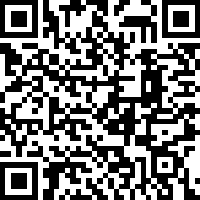